In [2]:
import sys, os

sys.path.append(os.path.abspath(os.path.join('..')))

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error



In [4]:
from src.data import load_csv

df = load_csv("../data/hour.csv")

In [5]:
features = ['atemp', 'hum', 'windspeed']
X_mlr = df[features]

X_slr = df[['atemp']]


Y = df['cnt']

In [6]:
## splitting dataset

X_train_slr, X_test_slr, y_train, y_test = train_test_split(X_slr, Y, test_size=0.25, random_state=42)

X_train_mlr, X_test_mlr, _, _ = train_test_split(X_mlr, Y, test_size=0.25, random_state=42)

In [7]:
def make_slr():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ('scale', StandardScaler()),
        ("model", LinearRegression())
    ])

def make_mlr():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", LinearRegression())
    ])

In [8]:
def bias_variance(model_factory, X_train, X_test, y_train, y_test, repeats=100, seed=42):
    rng = np.random.default_rng(seed)
    predictions = []
    X_train = X_train.reset_index(drop=True)
    y_train = y_train.reset_index(drop=True)

    n = len(X_train)

    for _ in range(repeats):

        indices = rng.integers(0, n, size=n)

        X_boot = X_train.iloc[indices]
        y_boot = y_train.iloc[indices]

        model = model_factory()
        model.fit(X_boot, y_boot)

        predictions.append(model.predict(X_test))

    predictions = np.asarray(predictions)

    average_prediction = predictions.mean(axis=0)
    y_true = np.asarray(y_test)

    bias_squared_proxy = np.mean(
        (average_prediction - y_true) ** 2
    )

    predictions_variance = np.mean(
        np.var(predictions, axis=0, ddof=0)
    )

    average_model_mse = np.mean(
        (predictions - y_true[None, :]) ** 2
    )

    return {
        "Bias² proxy": bias_squared_proxy,
        "Prediction Variance": predictions_variance,
        "Average Test MSE": average_model_mse,
        "Mean Predictions": average_prediction,
        "All predictions": predictions
    }


In [9]:
slr_result = bias_variance(make_slr, X_train_slr, X_test_slr, y_train, y_test, repeats=100, seed=42)

mlr_result = bias_variance(make_mlr, X_train_mlr, X_test_mlr, y_train, y_test, repeats=100, seed=42)

In [10]:
results_df = pd.DataFrame({
    "SLR (atemp)":{
        key: slr_result[key]
        for key in [
            "Bias² proxy",
            "Prediction Variance",
            "Average Test MSE"
        ]
    },
    "MLR (atemp, hum, windspeed)":{
        key: mlr_result[key]
        for key in [
            "Bias² proxy",
            "Prediction Variance",
            "Average Test MSE"
        ]
    }
}).T

print("\nBIAS-VARIANCE EXPERIMENT: SLR vs MLR")
print("=" * 75)
print(results_df.round(2))
print(type(results_df))


BIAS-VARIANCE EXPERIMENT: SLR vs MLR
                             Bias² proxy  Prediction Variance  \
SLR (atemp)                     26875.69                 3.71   
MLR (atemp, hum, windspeed)     23924.43                 6.53   

                             Average Test MSE  
SLR (atemp)                          26879.40  
MLR (atemp, hum, windspeed)          23930.96  
<class 'pandas.core.frame.DataFrame'>


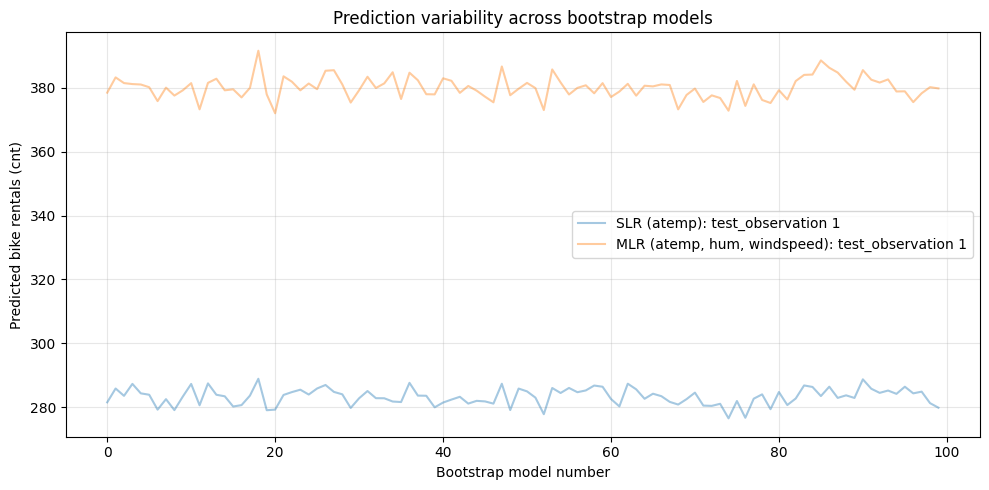

In [11]:
plt.figure(figsize=(10, 5))

for name, results_df in [
    ("SLR (atemp)", slr_result),
    ("MLR (atemp, hum, windspeed)", mlr_result)
]:
    all_preds = results_df["All predictions"]

    plt.plot(
        all_preds[:, 0],
        alpha= 0.4,
        label=f"{name}: test_observation 1"
    )

plt.xlabel("Bootstrap model number")
plt.ylabel("Predicted bike rentals (cnt)")
plt.title("Prediction variability across bootstrap models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
print(type(results_df))

<class 'dict'>


In [13]:

results_df = pd.DataFrame({
    "SLR (atemp)": {
        "Bias² proxy": slr_result["Bias² proxy"],
        "Prediction Variance": slr_result["Prediction Variance"],
        "Average Test MSE": slr_result["Average Test MSE"]
    },
    "MLR (atemp, hum, windspeed)": {
        "Bias² proxy": mlr_result["Bias² proxy"],
        "Prediction Variance": mlr_result["Prediction Variance"],
        "Average Test MSE": mlr_result["Average Test MSE"]
    }
}).T

print(type(results_df))  # Should be pandas DataFrame
print(results_df)


<class 'pandas.core.frame.DataFrame'>
                              Bias² proxy  Prediction Variance  \
SLR (atemp)                  26875.687006             3.708548   
MLR (atemp, hum, windspeed)  23924.425697             6.532731   

                             Average Test MSE  
SLR (atemp)                      26879.395554  
MLR (atemp, hum, windspeed)      23930.958428  


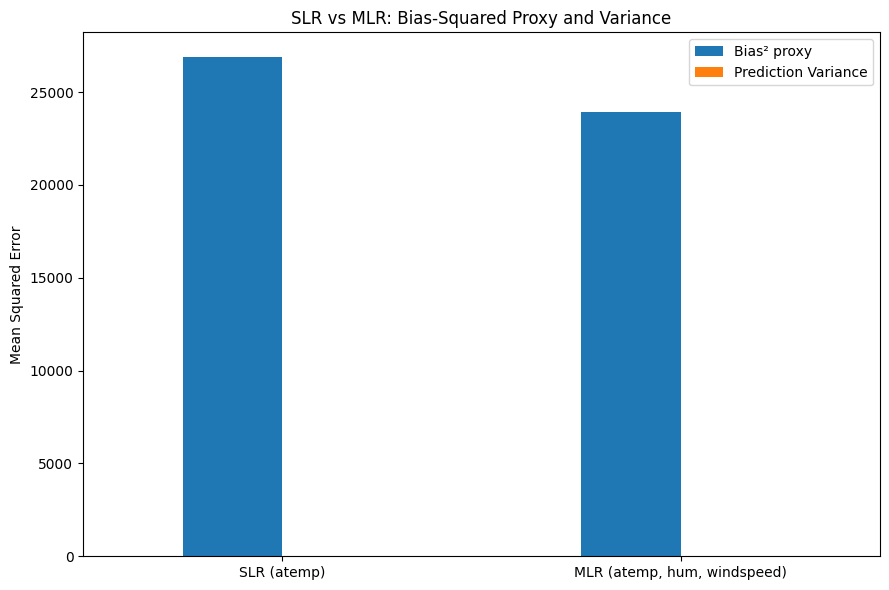

In [14]:
ax = results_df[
    ["Bias² proxy", "Prediction Variance"]
].plot(
    kind="bar",
    figsize=(9, 6)
)

ax.set_ylabel("Mean Squared Error")
ax.set_title("SLR vs MLR: Bias-Squared Proxy and Variance")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


   return {
        "Bias² proxy": bias_squared_proxy,
        "Prediction Variance": predictions_variance,
        "Average Test MSE": average_model_mse,
        "Mean Predictions": average_prediction,
        "All predictions": predictions
    }

In [15]:
## Polynomial Regression: model flexibility:

degrees = [1,2,3,4,5,6,7,8,9,10]
poly_results = []


for degree in degrees:

    def make_poly(d=degree):
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("poly", PolynomialFeatures(
                degree=d,
                include_bias=False
            )),
            ("scale", StandardScaler()),
            ("model", LinearRegression())
        ])

    result = bias_variance(
        make_poly,
        X_train_slr,
        X_test_slr,
        y_train,
        y_test,
        repeats=100,
        seed=42
    )

    poly_results.append({
        "Degree": degree,
        "Bias² proxy": result["Bias² proxy"],
        "Prediction Variance": result["Prediction Variance"],
        "Average Test MSE": result["Average Test MSE"]
    })

poly_df = pd.DataFrame(poly_results).set_index("Degree")

print("\nPOLYNOMIAL REGRESSION: MODEL FLEXIBILITY")
print("=" * 75)
print(poly_df.round(2))



POLYNOMIAL REGRESSION: MODEL FLEXIBILITY
        Bias² proxy  Prediction Variance  Average Test MSE
Degree                                                    
1          26875.69                 3.71          26879.40
2          26856.91                 5.31          26862.22
3          26797.31                 6.65          26803.97
4          26669.65                 7.24          26676.89
5          26634.47                10.03          26644.50
6          26606.16                11.12          26617.29
7          26555.81                19.39          26575.20
8          26545.27                30.11          26575.39
9          26533.55                25.23          26558.78
10         26528.52                30.97          26559.48


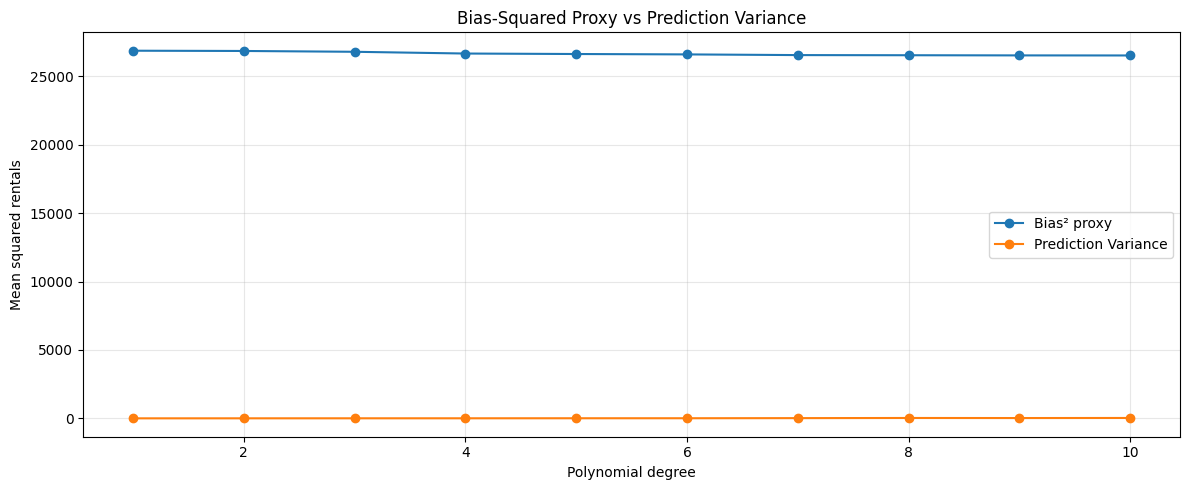

In [16]:
poly_df[
    ["Bias² proxy", "Prediction Variance"]
].plot(
    marker="o",
    figsize=(12, 5)
)

plt.xlabel("Polynomial degree")
plt.ylabel("Mean squared rentals")
plt.title("Bias-Squared Proxy vs Prediction Variance")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


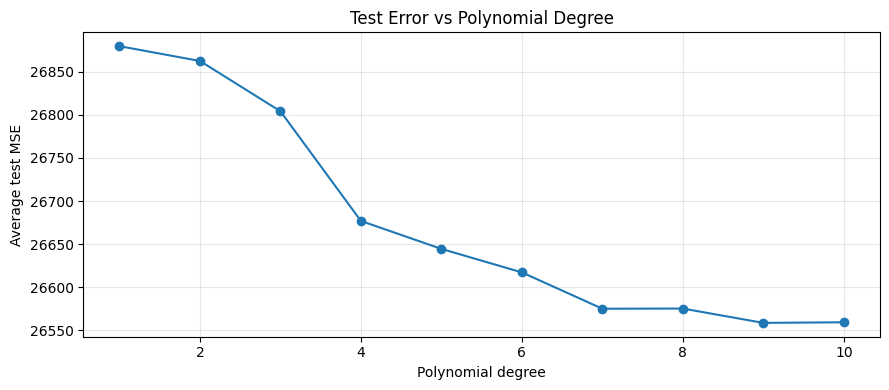

In [17]:
poly_df[
    ['Average Test MSE']
].plot(
    marker='o',
    legend=False,
    figsize=(9, 4)
)

plt.xlabel("Polynomial degree")
plt.ylabel("Average test MSE")
plt.title("Test Error vs Polynomial Degree")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



In [18]:

print("\nEXPERIMENT COMPLETE!")
print("Dataset: UCI Bike Sharing - hour.csv")
print("SLR feature: atemp")
print("MLR features: atemp, hum, windspeed")
print("Bootstrap repetitions: 100")
print("Polynomial degrees:", degrees)
print("\nNote: Bias² proxy uses observed test targets.")
print("It is NOT the exact theoretical bias² because")
print("the true underlying bike-rental function is unknown.")



EXPERIMENT COMPLETE!
Dataset: UCI Bike Sharing - hour.csv
SLR feature: atemp
MLR features: atemp, hum, windspeed
Bootstrap repetitions: 100
Polynomial degrees: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

Note: Bias² proxy uses observed test targets.
It is NOT the exact theoretical bias² because
the true underlying bike-rental function is unknown.


In [19]:
slr_result = bias_variance(make_slr, X_train_slr, X_test_slr, y_train, y_test, repeats=300, seed=42)

mlr_result = bias_variance(make_mlr, X_train_mlr, X_test_mlr, y_train, y_test, repeats=300, seed=42)

In [20]:
results_df = pd.DataFrame({
    "SLR (atemp)":{
        key: slr_result[key]
        for key in [
            "Bias² proxy",
            "Prediction Variance",
            "Average Test MSE"
        ]
    },
    "MLR (atemp, hum, windspeed)":{
        key: mlr_result[key]
        for key in [
            "Bias² proxy",
            "Prediction Variance",
            "Average Test MSE"
        ]
    }
}).T

print("\nBIAS-VARIANCE EXPERIMENT: SLR vs MLR")
print("=" * 75)
print(results_df.round(2))
print(type(results_df))


BIAS-VARIANCE EXPERIMENT: SLR vs MLR
                             Bias² proxy  Prediction Variance  \
SLR (atemp)                     26875.76                 3.78   
MLR (atemp, hum, windspeed)     23925.27                 7.14   

                             Average Test MSE  
SLR (atemp)                          26879.54  
MLR (atemp, hum, windspeed)          23932.41  
<class 'pandas.core.frame.DataFrame'>


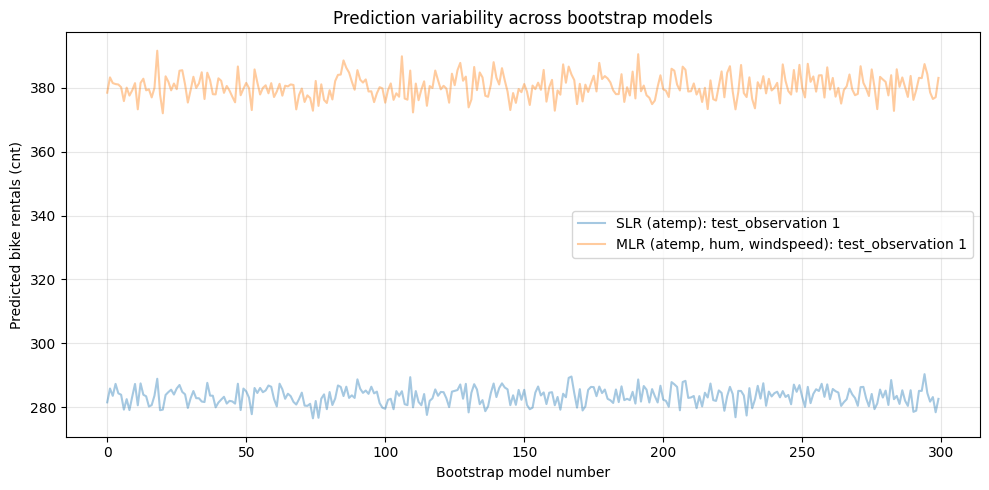

In [21]:
plt.figure(figsize=(10, 5))

for name, results_df in [
    ("SLR (atemp)", slr_result),
    ("MLR (atemp, hum, windspeed)", mlr_result)
]:
    all_preds = results_df["All predictions"]

    plt.plot(
        all_preds[:, 0],
        alpha= 0.4,
        label=f"{name}: test_observation 1"
    )

plt.xlabel("Bootstrap model number")
plt.ylabel("Predicted bike rentals (cnt)")
plt.title("Prediction variability across bootstrap models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:

results_df = pd.DataFrame({
    "SLR (atemp)": {
        "Bias² proxy": slr_result["Bias² proxy"],
        "Prediction Variance": slr_result["Prediction Variance"],
        "Average Test MSE": slr_result["Average Test MSE"]
    },
    "MLR (atemp, hum, windspeed)": {
        "Bias² proxy": mlr_result["Bias² proxy"],
        "Prediction Variance": mlr_result["Prediction Variance"],
        "Average Test MSE": mlr_result["Average Test MSE"]
    }
}).T

print(type(results_df))  # Should be pandas DataFrame
print(results_df)


<class 'pandas.core.frame.DataFrame'>
                              Bias² proxy  Prediction Variance  \
SLR (atemp)                  26875.760388             3.783798   
MLR (atemp, hum, windspeed)  23925.267592             7.139611   

                             Average Test MSE  
SLR (atemp)                      26879.544186  
MLR (atemp, hum, windspeed)      23932.407203  


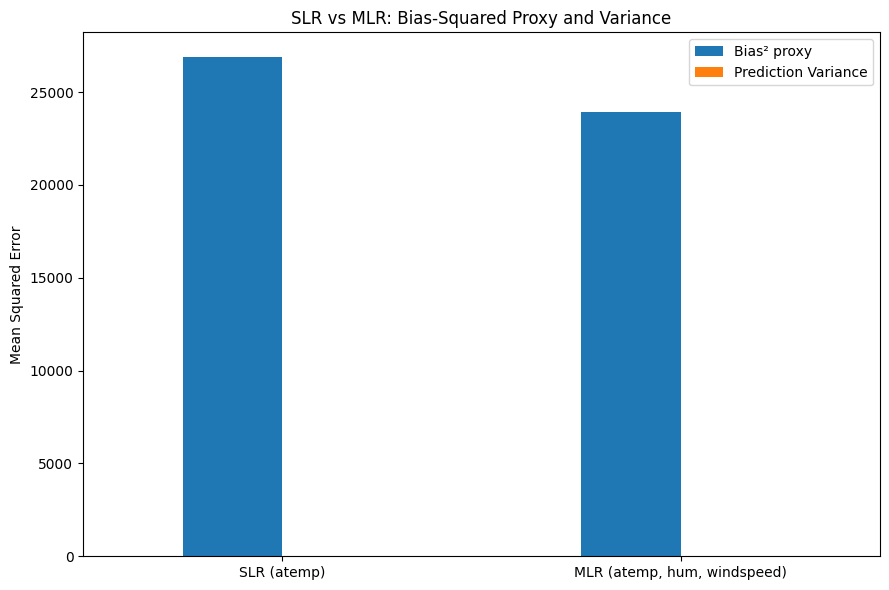

In [23]:
ax = results_df[
    ["Bias² proxy", "Prediction Variance"]
].plot(
    kind="bar",
    figsize=(9, 6)
)

ax.set_ylabel("Mean Squared Error")
ax.set_title("SLR vs MLR: Bias-Squared Proxy and Variance")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


### Part 1: Fake world:
This is recipe A from earlier. You make a curved truth plus noise, fit a straight line and a wiggly curve 200 times each, and plot the 200 faint lines. Write your bets first: which model wobbles more, and which is wrong on average?

line at x=0.3   bias= -0.561  variance= 0.015
line at x=0.05  bias= +0.558  variance= 0.040
wiggly at x=0.3   bias= -0.015  variance= 0.035
wiggly at x=0.05  bias= -0.107  variance= 11.246


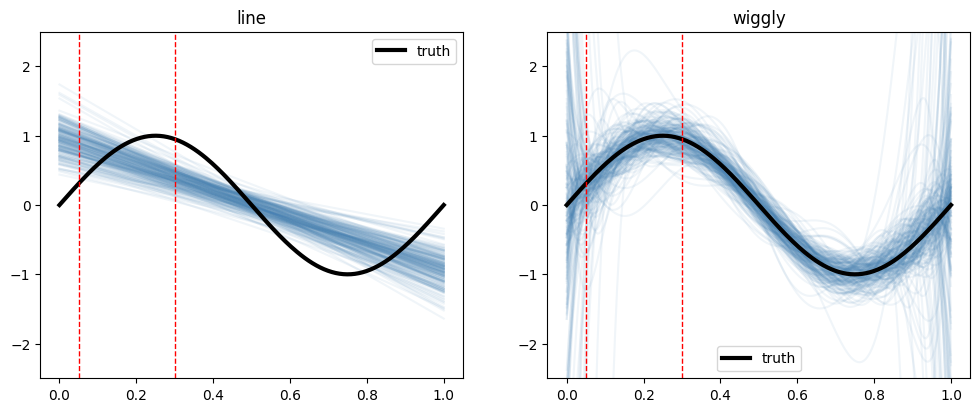

In [29]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

def truth(x):
    return np.sin(2 * np.pi * x)

n_points = 30
noise_sd = 0.3
n_repeats = 200
x_grid = np.linspace(0, 1, 200)
spots = [0.3, 0.05]

curves = {"line":[], "wiggly":[]}
preds_at_spot = {"line": {s : [] for s in spots},
                "wiggly": {s: [] for s in spots}}

for _ in range(n_repeats):
    x = rng.uniform(0, 1, n_points)
    y = truth(x) + rng.normal(0, noise_sd, n_points)

    fits = {
        "line": np.polyfit(x, y, 1),
        "wiggly": np.polyfit(x, y, 9)
    }

    for name, coef in fits.items():
        curves[name].append(np.polyval(coef, x_grid))
        for s in spots:
            preds_at_spot[name][s].append(np.polyval(coef, s))


for name in ["line", "wiggly"]:
    for s in spots:
        p = np.array(preds_at_spot[name][s])
        print(f"{name:.7s} at x={s:<5} bias= {p.mean() - truth(s):+.3f}  variance= {p.var():.3f}")

## the picture:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)
for ax, name in zip(axes, ["line", "wiggly"]):
    for c in curves[name]:
        ax.plot(x_grid, c, color="steelblue", alpha=0.08)
    ax.plot(x_grid, truth(x_grid), color="black", lw=3, label="truth")
    for s in spots:
        ax.axvline(s, color="red", ls="--", lw=1)

    ax.set_title(name)
    ax.set_ylim(-2.5, 2.5)
    ax.legend()
plt.show()


### Part 2: The bike sharing dataset.

In [30]:
from src.models import MultipleLinearRegression
df = df.copy()


Intercept  full_data=   164.43, wobble(std)=   6.69, wobble/size=0.040660
atemp      full_data=   406.03, wobble(std)=   7.30, wobble/size=0.017976
hum        full_data=  -279.31, wobble(std)=   7.14, wobble/size=0.025558
windspeed  full_data=    40.88, wobble(std)=  10.97, wobble/size=0.268492


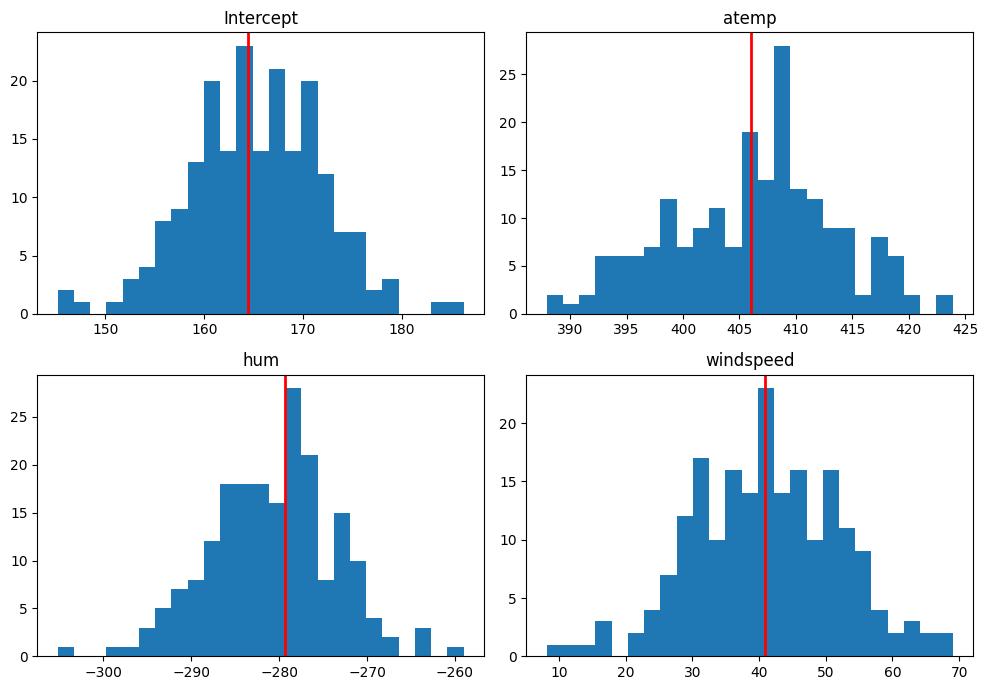

In [32]:
rng = np.random.default_rng(1)
X_array = np.asarray(X_train_mlr, dtype=float)
y_array = np.asarray(y_train, dtype=float)
n = len(X_array)

n_repeats = 200
all_betas = []

for _ in range(n_repeats):
    rows = rng.integers(0, n, size=n)
    model = MultipleLinearRegression().fit(X_array[rows], y_array[rows])
    all_betas.append(model.beta_hat)

all_betas = np.array(all_betas)

names = ["Intercept", "atemp", "hum", "windspeed"]
full_fit = MultipleLinearRegression().fit(X_array, y_array).beta_hat

for j, name in enumerate(names):
    col = all_betas[:, j]
    print(f"{name:10s} full_data={full_fit[j]:9.2f}, wobble(std)={col.std():7.2f}, wobble/size={col.std()/abs(full_fit[j]):3f}")

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for j, (ax, name) in enumerate(zip(axes.ravel(), names)):
    ax.hist(all_betas[:, j], bins=25)
    ax.axvline(full_fit[j], color="red", lw=2)
    ax.set_title(name)
plt.tight_layout()
plt.show()



My question is how must i interpret these numerical values, what is bias and variance i know,

see bias is how much are we away from the true relationship, and variance is how much the raltaion varies if we change the dataset, 

"the ability of the model to have a minimum loss function when dataset is changing " sorry this was optimisation

Instead, think of Variance as the model's sensitivity to the specific quirks of a training dataset. High variance meaning the model pays too much attention on the "NOISE" and random anomalies in training data, than to learn the pattern

Underfitting refers to when the model is not trained correctly on the training data and it ignores most of the things
BIAS: This underfitting term is called bias, bias == how much away we are form real/true relationship.

Overfitting : our model works best bes on training dataset but fails on real world data this is variance.

To balance them we use BIAS VARAINCE TRADEOFF finding balance between a model which is too simple and too complex